In [ ]:
library(Seurat)
library(CellChat)
library(tidyverse)
library(readxl)
library(patchwork)

In [ ]:
# 记录开始时间
start_time <- Sys.time()

In [ ]:
obj <- readRDS('/data/users/liyixin1/liyixin1_fb24a52625e34d2f8203d53f936822d4/online/毕业文章/Figure3/Glia/Glia-SGN/Merge-SGN_GLia.rds')

In [ ]:
obj
head(obj,3)

An object of class Seurat 
68980 features across 2145 samples within 2 assays 
Active assay: integrated (3000 features, 3000 variable features)
 1 other assay present: RNA
 2 dimensional reductions calculated: pca, umap

,orig.ident,nCount_RNA,nFeature_RNA,sample,percent.mt,RNA_snn_res.0.5,seurat_clusters,source,SN,RNA_snn_res.0.8,RNA_snn_res.0.4,RNA_snn_res.0.3,integrated_snn_res.0.3,celltype,celltype_0813,scDblFinder.class,scDblFinder.score,subtype_1004
,<chr>,<dbl>,<int>,<chr>,<dbl>,<chr>,<fct>,<chr>,<chr>,<chr>,<chr>,<chr>,<fct>,<chr>,<fct>,<fct>,<dbl>,<chr>
15520_4,SeuratProject,5857,2394,Y01818K9,0.1707359,NA,3,StereoCell,Y01818K9,0,NA,NA,3,1.SGN,2.SGN,singlet,0.14358014,2.nmSC2
11104_4,SeuratProject,8519,2519,Y01818K9,0.2582463,NA,3,StereoCell,Y01818K9,13,NA,NA,3,1.SGN,2.SGN,singlet,0.02045357,2.nmSC2
8109_4,SeuratProject,17805,4648,Y01818K9,0.1516428,NA,3,StereoCell,Y01818K9,5,NA,NA,3,1.SGN,2.SGN,singlet,0.05516464,2.nmSC2


In [ ]:
table(obj$subtype_1004)


           2.nmSC2            3.nmSC1              6.SGC             7.mSC1 
               741                521                344                268 
9.Oligodendrocytes             SGN-Ia             SGN-Ib             SGN-Ic 
                39                 54                 73                 69 
            SGN-II 
                36 

In [ ]:
#创建CellChat对象
options(future.globals.maxSize=10000000000)
cellchat <- createCellChat(object = obj@assays$RNA@data,
                           meta = obj@meta.data,
                           group.by = "subtype_1004")
cellchat <- setIdent(cellchat, ident.use = 'subtype_1004') #将label设置为显示的默认顺序


[1] "Create a CellChat object from a data matrix"
Set cell identities for the new CellChat object 
The cell groups used for CellChat analysis are  2.nmSC2 3.nmSC1 6.SGC 7.mSC1 9.Oligodendrocytes SGN-Ia SGN-Ib SGN-Ic SGN-II 


Rows: 3,395
Columns: 28
$ interaction_name         <chr> "TGFB1_TGFBR1_TGFBR2", "TGFB2_TGFBR1_TGFBR2",…
$ pathway_name             <chr> "TGFb", "TGFb", "TGFb", "TGFb", "TGFb", "TGFb…
$ ligand                   <chr> "Tgfb1", "Tgfb2", "Tgfb3", "Tgfb1", "Tgfb1", …
$ receptor                 <chr> "TGFbR1_R2", "TGFbR1_R2", "TGFbR1_R2", "ACVR1…
$ agonist                  <chr> "TGFb agonist", "TGFb agonist", "TGFb agonist…
$ antagonist               <chr> "TGFb antagonist", "TGFb antagonist", "TGFb a…
$ co_A_receptor            <chr> "", "", "", "", "", "", "", "", "", "", "", "…
$ co_I_receptor            <chr> "TGFb inhibition receptor", "TGFb inhibition …
$ evidence                 <chr> "KEGG: mmu04350", "KEGG: mmu04350", "KEGG: mm…
$ annotation               <chr> "Secreted Signaling", "Secreted Signaling", "…
$ interaction_name_2       <chr> "Tgfb1 - (Tgfbr1+Tgfbr2)", "Tgfb2  - (Tgfbr1+…
$ is_neurotransmitter      <lgl> FALSE, FALSE, FALSE, FALSE, FALSE, FALSE, FAL…
$ ligand.symbol 

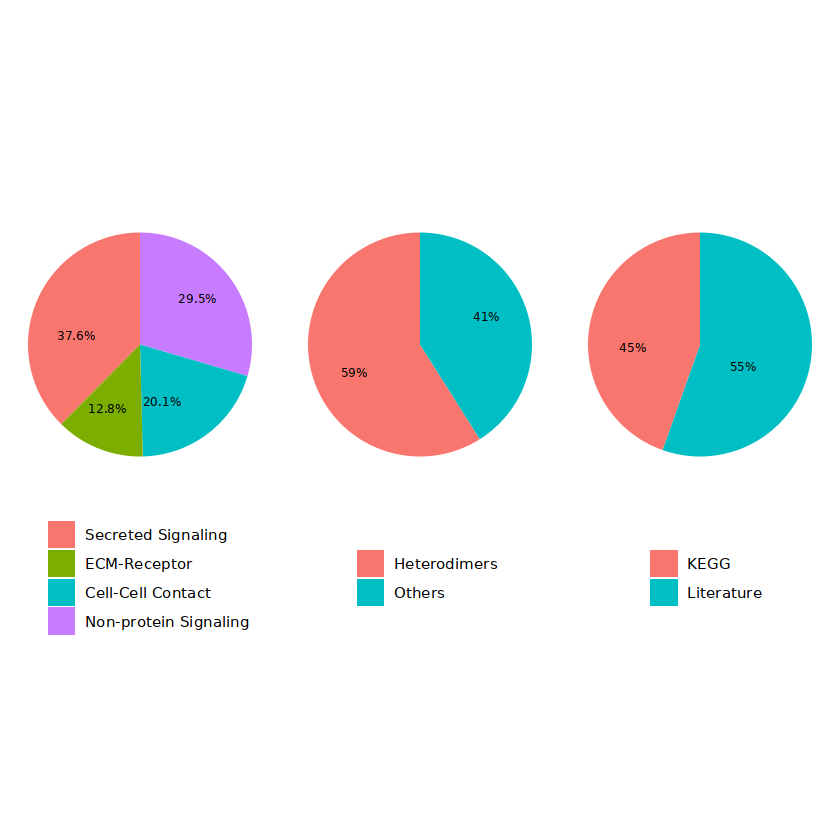

In [ ]:
#设置配受体数据库(CellChatDB):
CellChatDB <- CellChatDB.mouse #有人类(CellChatDB.human)和小鼠(CellChatDB.mouse)
showDatabaseCategory(CellChatDB) #查看描述该数据库组成的饼状图
dplyr::glimpse(CellChatDB$interaction) #查看数据库结构
#CellChatDB.use <- CellChatDB #直接使用CellChatDB全库进行细胞通讯分
CellChatDB.use <- subsetDB(CellChatDB, search = c("ECM-Receptor", 'Secreted Signaling', 'Cell-Cell Contact'))  #可选择Secreted Signaling、ECM-Receptor或Cell-Cell Contact
cellchat@DB <- CellChatDB.use

In [ ]:
# 数据预处理
cellchat <- subsetData(cellchat) #必选的step,取上一步CellChatDB.use中信号基因的表达矩阵子集,赋值到cellchat@data.Signaling
future::plan('multicore', workers = 32) # do parallel

cellchat <- identifyOverExpressedGenes(cellchat)
cellchat <- identifyOverExpressedInteractions(cellchat)

In [ ]:
# 计算结果赋值到cellchat@var.features：
# head(cellchat@var.features$features) #过表达信号基因名
# head(cellchat@var.features$features.info) #差异计算结果表
# cellchat <- projectData(cellchat, PPI.human) #将基因表达数据映射到PPI网络(可跳过);返回结果:cellchat@data.project


In [ ]:
#cellchat@data.signaling <- cellchat@data.signaling[rowSums(cellchat@data.signaling) > 0, , drop = FALSE]

In [ ]:
#########################——推断 cell-cell communication network——############################
# 计算细胞通讯概率
cellchat <- computeCommunProb(cellchat, raw.use = TRUE) #返回结果:cellchat@options$parameter;默认使用原始表达数据(cellchat@data.Signaling)，若想使用上一步PPI矫正数据,设置raw.use = TALSE
cellchat <- filterCommunication(cellchat, min.cells = 10) #细胞通讯过滤(设置每个亚群中进行细胞间通讯所需的最小细胞数)
cellchat <- computeCommunProbPathway(cellchat) #计算每个信号通路相关的所有配体-受体相互作用的通信结果
cellchat <- aggregateNet(cellchat) #计算细胞对间通讯的数量和概率强度
print("已计算computeCommunProb & computeCommunProbPathway")
saveRDS(cellchat,"Stereocell-SGN_Glia_cellchat.rds")
print("cellchat_plot.rds 已保存")

triMean is used for calculating the average gene expression per cell group. 
[1] ">>> Run CellChat on sc/snRNA-seq data <<< [2026-10-07 18:18:15]"
[1] ">>> CellChat inference is done. Parameter values are stored in `object@options$parameter` <<< [2026-10-07 18:27:42]"
[1] "已计算computeCommunProb & computeCommunProbPathway"
[1] "cellchat_plot.rds 已保存"


In [ ]:
cellchat <- readRDS('Stereocell-SGN_Glia_cellchat.rds')

In [ ]:
id <- 'Stereocell-SGN_Glia'

In [ ]:
groupSize <- as.numeric(table(cellchat@idents))

pdf(paste0(id, "-all-subcellttpe_netVisual_circle.pdf"))
#par(mfrow = c(1,2), xpd=TRUE)
p <- netVisual_circle(cellchat@net$count, vertex.weight = groupSize, weight.scale = T, label.edge= F, title.name = "Number of interactions")
print(p)
p <- netVisual_circle(cellchat@net$weight, vertex.weight = groupSize, weight.scale = T, label.edge= F, title.name = "Interaction weights/strength")
print(p)
dev.off()

png 
  2

In [ ]:
#逐个展示细胞亚群的互作信号强度——网图：
mat <- cellchat@net$weight
pdf(paste0(id, "-every-subcellttpe_netVisual_circle.pdf"))
lapply(1:nrow(mat), function(i) {
  mat2 <- matrix(0, nrow = nrow(mat), ncol = ncol(mat), dimnames = dimnames(mat))
  mat2[i, ] <- mat[i, ]
  p <- netVisual_circle(mat2, vertex.weight = groupSize, weight.scale = T, edge.weight.max = max(mat), title.name = rownames(mat)[i], edge.label.cex = 0.4, vertex.label.cex = 0.5)
  return(p)
})
dev.off()

[[1]]

[[2]]

[[3]]

[[4]]

[[5]]

[[6]]

[[7]]

[[8]]

[[9]]


png 
  2

In [ ]:
#逐个展示细胞亚群的互作信号强度——柱状图：
pdf(paste0(id, "-every-subcelltype_barplot.pdf"))
lapply(1:nrow(mat), function(i) {
  # 创建数据框
  df <- data.frame(cell_type = colnames(mat), weight = as.numeric(mat[i, ]))
  # 使用ggplot2创建柱状图
  p <- ggplot(df, aes(x = cell_type, y = weight, fill = cell_type)) +
    geom_bar(stat = "identity",fill = "steelblue", width=0.3) +
    labs(title = rownames(mat)[i], x = "celltype", y = "Signal Strength") +
    theme_classic() +
    theme(axis.text.x = element_text(angle = 45, hjust = 1), axis.text = element_text(size = 8)) 
  return(p)
})
dev.off()

[[1]]

[[2]]

[[3]]

[[4]]

[[5]]

[[6]]

[[7]]

[[8]]

[[9]]


png 
  2

In [ ]:
# 逐个信号通路展示：细胞亚群的互作
path <- unique(cellchat@netP$pathways)

lapply(path,function(pathways.show){
  try({
    pdf(
      paste0("pathway-",pathways.show,".pdf"),
      width=10,
      height=10,
      onefile=TRUE
    )

    # 1. Circle
    netVisual_aggregate(
      cellchat,
      signaling=pathways.show,
      layout="circle"
    )

    # 2. Heatmap
    grid::grid.newpage()
    p1 <- netVisual_heatmap(
      cellchat,
      signaling=pathways.show,
      color.heatmap="Reds"
    )
    print(p1)

    # 3. L-R contribution
    grid::grid.newpage()
    p2 <- netAnalysis_contribution(
      cellchat,
      signaling=pathways.show
    )
    print(p2)

    # 4. Signaling role
    grid::grid.newpage()

    extractEnrichedLR(
      cellchat,
      signaling=pathways.show,
      geneLR.return=FALSE
    )

    cellchat <- netAnalysis_computeCentrality(
      cellchat,
      slot.name="netP"
    )

    netAnalysis_signalingRole_network(
      cellchat,
      signaling=pathways.show,
      width=15,
      height=2.5,
      font.size=10
    )

    dev.off()

  },silent=FALSE)
})

Do heatmap based on a single object 


Do heatmap based on a single object 


Do heatmap based on a single object 


Do heatmap based on a single object 


Do heatmap based on a single object 


Do heatmap based on a single object 


Do heatmap based on a single object 


Do heatmap based on a single object 


Do heatmap based on a single object 


Do heatmap based on a single object 


Do heatmap based on a single object 


Do heatmap based on a single object 


Do heatmap based on a single object 


Do heatmap based on a single object 


Do heatmap based on a single object 


Do heatmap based on a single object 


Do heatmap based on a single object 


Do heatmap based on a single object 


Do heatmap based on a single object 


Do heatmap based on a single object 


Do heatmap based on a single object 


Do heatmap based on a single object 


Do heatmap based on a single object 


Do heatmap based on a single object 


Do heatmap based on a single object 


Do heatmap based on a sin

[[1]]
png 
  2 

[[2]]
png 
  2 

[[3]]
png 
  2 

[[4]]
png 
  2 

[[5]]
png 
  2 

[[6]]
png 
  2 

[[7]]
png 
  2 

[[8]]
png 
  2 

[[9]]
png 
  2 

[[10]]
png 
  2 

[[11]]
png 
  2 

[[12]]
png 
  2 

[[13]]
png 
  2 

[[14]]
png 
  2 

[[15]]
png 
  2 

[[16]]
png 
  2 

[[17]]
png 
  2 

[[18]]
png 
  2 

[[19]]
png 
  2 

[[20]]
png 
  2 

[[21]]
png 
  2 

[[22]]
png 
  2 

[[23]]
png 
  2 

[[24]]
png 
  2 

[[25]]
png 
  2 

[[26]]
png 
  2 

[[27]]
png 
  2 

[[28]]
png 
  2 

[[29]]
png 
  2 

[[30]]
png 
  2 

[[31]]
png 
  2 

[[32]]
png 
  2 

[[33]]
png 
  2 

[[34]]
png 
  2 

[[35]]
png 
  2 

[[36]]
png 
  2 

[[37]]
png 
  2 

[[38]]
png 
  2 

[[39]]
png 
  2 

[[40]]
png 
  2 

[[41]]
png 
  2 

[[42]]
png 
  2 

[[43]]
png 
  2 

[[44]]
png 
  2 

[[45]]
png 
  2 

[[46]]
png 
  2 

[[47]]
png 
  2 

[[48]]
png 
  2 

[[49]]
png 
  2 

[[50]]
png 
  2 

[[51]]
png 
  2 

[[52]]
png 
  2

In [ ]:
sgn.use <- c(
  "SGN-Ic","SGN-Ib",
  "SGN-Ia","SGN-II"
)

glia.use <- c(
  "2.nmSC2","3.nmSC1",
  "6.SGC","7.mSC1","9.Oligodendrocytes"
)

stopifnot(
  all(c(sgn.use,glia.use) %in% levels(cellchat@idents))
)

# Glia → SGN
p1 <- netVisual_bubble(
  cellchat,
  sources.use=glia.use,
  targets.use=sgn.use,
  remove.isolate=TRUE,
  angle.x=45
)

ggsave(
  "CellChat_Glia_to_SGN_bubble.pdf",
  p1,width=12,height=20
)

# SGN → Glia
p2 <- netVisual_bubble(
  cellchat,
  sources.use=sgn.use,
  targets.use=glia.use,
  remove.isolate=TRUE,
  angle.x=45
)

ggsave(
  "CellChat_SGN_to_Glia_bubble.pdf",
  p2,width=12,height=20
)

Comparing communications on a single object 


Comparing communications on a single object 




In [ ]:
# 所有显著配体–受体通讯
lr <- subsetCommunication(cellchat)

# 只保留 SGN 与 Glia 之间的两个方向
lr.cross <- lr[
  (lr$source %in% sgn.use & lr$target %in% glia.use) |
  (lr$source %in% glia.use & lr$target %in% sgn.use),
]

write.csv(
  lr.cross,
  "SGN_Glia_bidirectional_LR.csv",
  row.names = FALSE
)

# 导出强度矩阵，用于核实图中的强弱
write.csv(
  cellchat@net$weight,
  "CellChat_interaction_weights.csv"
)

In [ ]:
library(ggplot2)
library(dplyr)

input_file <- "SGN_Glia_bidirectional_LR.csv"

output_dir <- "CellChat_pathway_bubbles"
dir.create(output_dir, recursive = TRUE, showWarnings = FALSE)

lr <- read.csv(
  input_file,
  stringsAsFactors = FALSE,
  check.names = FALSE
)

required_cols <- c(
  "source", "target", "prob", "pval",
  "interaction_name", "interaction_name_2", "pathway_name"
)

stopifnot(all(required_cols %in% colnames(lr)))

pathways <- c(
  "ADGRL", "CADM", "LAMININ",
  "NCAM", "NRG", "NRXN", "PTPR",
  "CNTN", "SLIT", "LAMININ",
  "ADGRG", "GAS", "PSAP", "FGF", "SPP1"
)

sgn <- c(
  "SGN-Ic","SGN-Ib",
  "SGN-Ia","SGN-II"
)

glia <- c(
  "2.nmSC2",
  "3.nmSC1",
  "6.SGC",
  "7.mSC1",
  "9.Oligodendrocytes"
)

# 只保留 SGN 与 Glia 之间、p < 0.05 且 prob > 0 的记录
lr <- lr %>%
  filter(
    pathway_name %in% pathways,
    is.finite(prob),
    is.finite(pval),
    prob > 0,
    pval < 0.05,
    (source %in% glia & target %in% sgn) |
      (source %in% sgn & target %in% glia)
  )

if (nrow(lr) == 0) {
  stop("没有符合条件的通讯记录，请检查细胞标签和通路名称。")
}

# 检查同一细胞对内是否有重复相互作用
if (anyDuplicated(
  lr[, c("source", "target", "interaction_name")]
) > 0) {
  stop("发现重复的 source-target-interaction_name，请先检查数据。")
}

# 所有图使用相同的颜色范围
prob_max <- max(lr$prob)

make_bubble <- function(pathway, sources, targets, direction) {

  df <- lr %>%
    filter(
      pathway_name == pathway,
      source %in% sources,
      target %in% targets
    )

  # 没有结果时保留一页说明，避免静默跳过
  if (nrow(df) == 0) {
    return(
      ggplot() +
        annotate(
          "text",
          x = 0, y = 0,
          label = "No retained interactions (p < 0.05)"
        ) +
        labs(title = paste(pathway, direction, sep = " | ")) +
        theme_void()
    )
  }

  # X 轴：按发送群分组，保留所有指定的细胞组合
  x_levels <- unlist(
    lapply(
      sources,
      function(s) paste(s, targets, sep = " -> ")
    ),
    use.names = FALSE
  )

  # Y 轴：该方向实际检出的全部配体–受体对
  # 使用唯一 interaction_name 定位，显示可读的分子对名称
  pair_table <- df %>%
    distinct(interaction_name, interaction_name_2) %>%
    arrange(interaction_name_2)

  pair_labels <- setNames(
    pair_table$interaction_name_2,
    pair_table$interaction_name
  )

  df <- df %>%
    mutate(
      cell_pair = factor(
        paste(source, target, sep = " -> "),
        levels = x_levels
      ),

      interaction_id = factor(
        interaction_name,
        levels = rev(pair_table$interaction_name)
      ),

      p_group = factor(
        ifelse(pval < 0.01, "p < 0.01", "0.01 <= p < 0.05"),
        levels = c("p < 0.01", "0.01 <= p < 0.05")
      )
    )

  ggplot(
    df,
    aes(x = cell_pair, y = interaction_id)
  ) +
    geom_point(
      aes(color = prob, size = p_group),
      alpha = 0.95
    ) +
    scale_color_gradientn(
      colours = c(
        "#29409E", "#1A99B8", "#8FCC A3",
        "#FCD462", "#C71A29"
      ) |> gsub(pattern = " ", replacement = ""),
      limits = c(0, prob_max),
      name = "Raw prob"
    ) +
    scale_size_manual(
      values = c(
        "p < 0.01" = 3.2,
        "0.01 <= p < 0.05" = 1.9
      ),
      drop = FALSE,
      name = "p-value"
    ) +
    scale_x_discrete(drop = FALSE) +
    scale_y_discrete(labels = pair_labels) +
    labs(
      title = paste(pathway, direction, sep = " | "),
      subtitle = paste0(
        nrow(pair_table), " ligand-receptor pairs; ",
        nrow(df), " communications"
      ),
      x = NULL,
      y = NULL,
      caption = paste(
        "All detected pairs in this direction; p < 0.05.",
        "Colors use a common raw-probability scale."
      )
    ) +
    theme_bw(base_size = 10) +
    theme(
      axis.text.x = element_text(
        angle = 55, hjust = 1, vjust = 1, size = 8
      ),
      axis.text.y = element_text(size = 9),
      panel.grid.minor = element_blank(),
      panel.grid.major = element_line(
        colour = "#E1E6EC", linewidth = 0.3
      ),
      plot.title = element_text(face = "bold"),
      plot.caption = element_text(hjust = 0, size = 8),
      plot.margin = margin(12, 15, 12, 12)
    )
}

plots <- list()

for (pw in pathways) {

  plots[[paste0(pw, "_Glia_to_SGN")]] <- make_bubble(
    pathway = pw,
    sources = glia,
    targets = sgn,
    direction = "Glia -> SGN"
  )

  plots[[paste0(pw, "_SGN_to_Glia")]] <- make_bubble(
    pathway = pw,
    sources = sgn,
    targets = glia,
    direction = "SGN -> Glia"
  )
}

# 安全关闭 PDF 设备
save_pdf <- function(plot_list, filename, width, height) {

  grDevices::pdf(
    file = filename,
    width = width,
    height = height,
    onefile = TRUE,
    useDingbats = FALSE
  )

  on.exit(grDevices::dev.off(), add = TRUE)

  for (p in plot_list) {
    print(p)
  }
}

for (pw in pathways) {

  keys <- c(
    paste0(pw, "_Glia_to_SGN"),
    paste0(pw, "_SGN_to_Glia")
  )

  # 根据该通路两个方向中较多的分子对数量调整高度
  n_pairs <- vapply(
    plots[keys],
    function(p) {
      if ("interaction_id" %in% names(p$data)) {
        nlevels(p$data$interaction_id)
      } else {
        0L
      }
    },
    integer(1)
  )

  plot_height <- max(6, 3.5 + 0.22 * max(n_pairs))

  save_pdf(
    plot_list = plots[keys],
    filename = file.path(
      output_dir,
      paste0(pw, "_bidirectional_bubble.pdf")
    ),
    width = 14,
    height = plot_height
  )
}

save_pdf(
  plot_list = plots,
  filename = file.path(
    output_dir,
    "All_pathways_bubbles.pdf"
  ),
  width = 14,
  height = 13
)

message("绘图完成，文件保存在：", output_dir)

绘图完成，文件保存在：CellChat_pathway_bubbles



In [ ]:
selected_pairs <- function() {
  make <- function(direction, text) {
    z <- read.table(text = text, sep = '|', header = FALSE,
                    stringsAsFactors = FALSE, quote = '', strip.white = TRUE)
    names(z) <- c('family', 'ligand', 'receptor')
    z$direction <- direction
    z$pair <- paste(z$ligand, z$receptor, sep = ' - ')
    z
  }
  rbind(
    make('Glia -> SGN', 'CNTN/NFASC|Cntn2|(Cntn2+Cntnap2)
CNTN/NFASC|Nfasc|(Cntn1+Cntnap1)
SLIT|Slit2|Robo1
LAMININ|Lama1|Sv2b
LAMININ|Lama1|Sv2c
LAMININ|Lama2|Cd44
LAMININ|Lama2|Sv2b
LAMININ|Lama2|Sv2c
LAMININ|Lamc1|Sv2b
LAMININ|Lamc1|Sv2c
FGF|Fgf1|Fgfr1
FGF|Fgf1|Fgfr2
SPP1|Spp1|Cd44'),
    make('SGN -> Glia', 'CNTN/NFASC|Cntn1|Notch2
CNTN/NFASC|Cntn1|Nrcam
SLIT|Slit2|Robo1
LAMININ|Lama2|Cd44
LAMININ|Lama2|Dag1
LAMININ|Lamc1|Cd44
LAMININ|Lamc1|Dag1
PSAP|Psap|Gpr37
FGF|Fgf1|Fgfr1
FGF|Fgf1|Fgfr2
FGF|Fgf10|Fgfr1
FGF|Fgf10|Fgfr2
FGF|Fgf9|Fgfr2
SPP1|Spp1|Cd44
SPP1|Spp1|(Itgav+Itgb5)
SPP1|Spp1|(Itgav+Itgb1)')
  )
}

# Ignore case, spaces, parentheses, and common Unicode punctuation.
pair_key <- function(x) {
  for (ch in c('\u2212', '\u2013', '\u2014')) x <- gsub(ch, '-', x, fixed = TRUE)
  x <- gsub('\uff0b', '+', x, fixed = TRUE)
  x <- gsub('[[:space:]()\uff08\uff09]', '', x, perl = TRUE)
  toupper(x)
}

prepare_ABCD <- function(input_file = 'SGN_Glia_bidirectional_LR.csv',
                         output_dir = 'CellChat_selected_ABCD') {
  if (!requireNamespace('ggplot2', quietly = TRUE)) stop('Install ggplot2 first.')
  x <- read.csv(input_file, stringsAsFactors = FALSE, check.names = FALSE)
  need <- c('source', 'target', 'prob', 'pval', 'interaction_name_2')
  if (!all(need %in% names(x))) stop('Missing columns: ', paste(setdiff(need, names(x)), collapse=', '))
  if (!is.numeric(x$prob) || !is.numeric(x$pval)) stop('prob and pval must be numeric.')
  sgn <- c(  "SGN-Ic","SGN-Ib","SGN-Ia","SGN-II")
  glia <- c('2.nmSC2', '3.nmSC1', '6.SGC', '7.mSC1', '9.Oligodendrocytes')
  x$direction <- ifelse(x$source %in% glia & x$target %in% sgn, 'Glia -> SGN',
                 ifelse(x$source %in% sgn & x$target %in% glia, 'SGN -> Glia', NA_character_))
  x$key <- pair_key(x$interaction_name_2)
  spec <- selected_pairs(); spec$key <- pair_key(spec$pair)
  x$selection_index <- match(paste(x$direction, x$key), paste(spec$direction, spec$key))
  matched <- x[!is.na(x$selection_index), , drop = FALSE]
  keep <- is.finite(matched$prob) & matched$prob > 0 & is.finite(matched$pval) & matched$pval < .05
  sig <- matched[keep, , drop = FALSE]
  if (anyDuplicated(sig[c('source', 'target', 'key')])) {
    stop('Multiple records map to the same cell pair and molecular pair; inspect before plotting.')
  }
  if (!nrow(sig)) stop('No matched significant pairs. Check labels and interaction_name_2.')
  dir.create(output_dir, recursive = TRUE, showWarnings = FALSE)
  spec$matched_records <- vapply(seq_len(nrow(spec)), function(i) sum(matched$selection_index == i), integer(1))
  spec$significant_records <- vapply(seq_len(nrow(spec)), function(i) sum(sig$selection_index == i), integer(1))
  spec$status <- ifelse(spec$matched_records == 0, 'Not found in input CSV',
                       ifelse(spec$significant_records == 0, 'No retained p<0.05 record', 'Detected'))
  write.csv(spec, file.path(output_dir, 'Selected_pair_match_check.csv'), row.names = FALSE)
  write.csv(sig, file.path(output_dir, 'Selected_LR_records.csv'), row.names = FALSE)
  if (any(spec$significant_records == 0)) {
    warning('Some requested pairs have no retained records. See Selected_pair_match_check.csv; their rows are kept blank.')
  }
  list(spec=spec, sig=sig, sgn=sgn, glia=glia, out=output_dir, prob_max=max(sig$prob))
}

prob_scale <- function(cfg, fill=FALSE) {
  args <- list(colours=c('#29409E','#1A99B8','#8FCCA3','#FCD462','#C71A29'),
               limits=c(0,cfg$prob_max), name='Raw prob', na.value='#E8E8E8')
  do.call(if (fill) ggplot2::scale_fill_gradientn else ggplot2::scale_color_gradientn, args)
}

save_pages <- function(filename, pages, width, height) {
  grDevices::pdf(filename, width=width, height=height, onefile=TRUE, useDingbats=FALSE)
  on.exit(grDevices::dev.off(), add=TRUE)
  for (p in pages) print(p)
}


plot_D <- function(cfg, obj, group.by='subtype_1004', assay='RNA') {
  if (!requireNamespace('Seurat',quietly=TRUE)) stop('Install Seurat first.')
  if (!inherits(obj,'Seurat')) stop('obj must be the mouse SGN-Glia Seurat object.')
  if (!group.by %in% colnames(obj[[]])) stop('Missing grouping column: ',group.by)
  if (!assay %in% SeuratObject::Assays(obj)) stop('Missing assay: ',assay)
  if (inherits(obj[[assay]],'Assay5')) {
    ls <- SeuratObject::Layers(obj[[assay]],search=NA)
    dl <- ls[grepl('^data($|\\.)',ls)]
    if (length(dl)!=1 || dl!='data') stop('RNA has no single data layer. Inspect Layers(obj[["RNA"]]); join normalized data layers if appropriate before D.')
  }
  mat <- SeuratObject::GetAssayData(obj,assay=assay,slot='data')
  if (!nrow(mat) || !ncol(mat)) stop('RNA data is empty; normalized expression is required.')
  groups <- c(cfg$glia,cfg$sgn)
  meta <- obj[[]]
  if (!all(groups %in% as.character(meta[[group.by]]))) stop('Expected SGN/Glia labels missing. Check object identity and group.by.')
  cells <- rownames(meta)[!is.na(meta[[group.by]]) & meta[[group.by]] %in% groups]
  obj.plot <- subset(obj,cells=cells)
  obj.plot[[group.by]] <- factor(obj.plot[[]][[group.by]],levels=groups)
  split_genes <- function(x) unique(trimws(unlist(strsplit(gsub('[()]','',x),'\\+'))))
  pages <- list(); audit <- list(); max_genes <- 0
  for (direction in unique(cfg$spec$direction)) {
    sp <- cfg$spec[cfg$spec$direction==direction, , drop=FALSE]
    for (role in c('ligand','receptor')) {
      genes <- split_genes(sp[[role]])
      present <- genes %in% rownames(mat)
      audit[[length(audit)+1]] <- data.frame(direction=direction,role=role,gene=genes,in_RNA=present)
      if (any(!present)) warning('Genes absent from RNA: ',paste(genes[!present],collapse=', '))
      genes <- genes[present]; if (!length(genes)) stop('No genes found for ',direction,' ',role)
      max_genes <- max(max_genes,length(genes))
      p <- Seurat::DotPlot(obj.plot,features=genes,assay=assay,group.by=group.by,
        scale=FALSE,col.min=0,col.max=Inf,dot.scale=6) +
        ggplot2::scale_color_gradient(low='#E2EAF2',high='#B71935',name='Average expression\n(log1p; unscaled)') +
        ggplot2::labs(title=paste('D',direction,role,sep=' | '),x=NULL,y=NULL,
          caption='All requested genes; complexes split into subunits. Dot size = % expressing cells. Colors are not gene-wise Z-scores.') +
        ggplot2::theme(axis.text.x=ggplot2::element_text(angle=55,hjust=1),plot.title=ggplot2::element_text(face='bold'))
      pages[[length(pages)+1]] <- p
    }
  }
  # A shared expression color range across all four pages.
  vmax <- max(vapply(pages,function(p) max(p$data$avg.exp.scaled,na.rm=TRUE),numeric(1)))
  for (i in seq_along(pages)) {
    pages[[i]] <- pages[[i]] + ggplot2::scale_color_gradient(low='#E2EAF2',high='#B71935',limits=c(0,vmax),name='Average expression\n(log1p; unscaled)') +
      ggplot2::scale_size(range=c(0,6),limits=c(0,100),breaks=c(0,25,50,75,100),name='% expressing')
    ggplot2::ggsave(file.path(cfg$out,paste0('D_expression_',i,'.pdf')),pages[[i]],width=max(10,.42*max_genes+4),height=6,limitsize=FALSE)
    write.csv(pages[[i]]$data,file.path(cfg$out,paste0('D_expression_',i,'_data.csv')),row.names=FALSE)
  }
  write.csv(do.call(rbind,audit),file.path(cfg$out,'D_gene_presence_check.csv'),row.names=FALSE)
  save_pages(file.path(cfg$out,'D_all_expression_DotPlots.pdf'),pages,max(10,.42*max_genes+4),6)
  invisible(pages)
}

In [ ]:
# 读取通讯结果，匹配你选中的分子对
cfg <- prepare_ABCD(
  input_file = "SGN_Glia_bidirectional_LR.csv",
  output_dir = "CellChat_selected_ABCD"
)

# 检查是否匹配成功
cfg$spec[, c(
  "direction", "pair",
  "significant_records", "status"
)]

direction,pair,significant_records,status
<chr>,<chr>,<int>,<chr>
Glia -> SGN,Cntn2 - (Cntn2+Cntnap2),4,Detected
Glia -> SGN,Nfasc - (Cntn1+Cntnap1),15,Detected
Glia -> SGN,Slit2 - Robo1,11,Detected
Glia -> SGN,Lama1 - Sv2b,9,Detected
Glia -> SGN,Lama1 - Sv2c,9,Detected
Glia -> SGN,Lama2 - Cd44,0,Not found in input CSV
Glia -> SGN,Lama2 - Sv2b,15,Detected
Glia -> SGN,Lama2 - Sv2c,15,Detected
Glia -> SGN,Lamc1 - Sv2b,15,Detected



           2.nmSC2            3.nmSC1              6.SGC             7.mSC1 
               741                521                344                268 
9.Oligodendrocytes             SGN-Ia             SGN-Ib             SGN-Ic 
                39                 54                 73                 69 
            SGN-II 
                36 

Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for size is already present.
Adding another scale for size, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for size is already present.
Adding another scale for size, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for size is already p

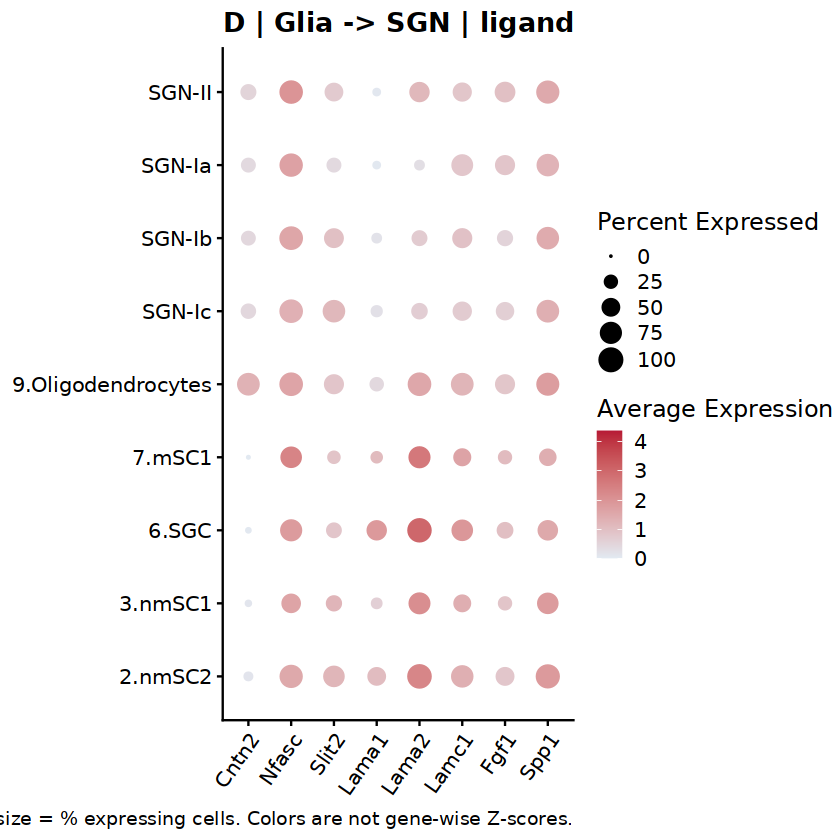

In [ ]:
# 先确认对象和分组
table(obj$subtype_1004)

# 自动提取全部选中分子对的基因，并拆开复合受体亚基
plots_D <- plot_D(
  cfg,
  obj = obj,
  group.by = "subtype_1004",
  assay = "RNA"
)

# 预览第一页
print(plots_D[[1]])

In [ ]:
cellchat <- readRDS('/data/work/Stereocell/SGN-Glia/Stereocell-SGN_Glia_cellchat.rds')

In [ ]:
# 不使用之前筛选配对得到的 cfg_epi
net_weight <- cellchat@net$weight
net_count  <- cellchat@net$count

# 保留最强的约50%连线；改为0.3会更稀疏，0.7会更密集
#keep_fraction <- 0.48
keep_fraction <- 0.5

positive_weights <- net_weight[
  is.finite(net_weight) & net_weight > 0
]

if (!length(positive_weights)) stop("没有可绘制的互作。")

cutoff <- unname(
  quantile(positive_weights, probs = 1 - keep_fraction)
)

# 数量图、强度图使用同一套连线
keep <- is.finite(net_weight) &
        net_weight > 0 &
        net_weight >= cutoff

net_weight[!keep] <- 0
net_count[!keep]  <- 0

# 节点大小表示各群细胞数
group_size <- as.numeric(
  table(cellchat@idents)[rownames(net_weight)]
)

plot_circle <- function(net, title) {
  CellChat::netVisual_circle(
    net,
    vertex.weight = group_size,
    vertex.size.max = 20,
    vertex.label.cex = 0.9,
    weight.scale = TRUE,
    edge.width.max = 8,
    edge.curved = 0.2,
    arrow.size = 0.3,
    label.edge = FALSE,
    remove.isolate = FALSE,
    title.name = title
  )
}

In [ ]:
library(igraph)

# 数量图：自环朝节点外侧展开
save_count_circle <- function(
    filename = "SGN_Glia_all_pathways_filtered_count.pdf") {

  mat <- as.matrix(net_count)
  mat[!is.finite(mat)] <- 0

  g <- graph_from_adjacency_matrix(
    mat, mode = "directed", weighted = TRUE, diag = TRUE
  )

  if (ecount(g) == 0) stop("没有可绘制的连线。")

  node_colors <- setNames(
    rep_len(
      c("#E41A1C", "#377EB8", "#4DAF4A",
        "#984EA3", "#F29403", "#F781BF", "#BC9DCC"),
      vcount(g)
    ),
    V(g)$name
  )

  n_cells <- as.numeric(
    table(cellchat@idents)[V(g)$name]
  )

  if (anyNA(n_cells) || max(n_cells) <= 0) {
    stop("细胞群名称与 cellchat@idents 不匹配。")
  }

  sender <- ends(g, E(g), names = TRUE)[, 1]

  # 圆形布局及朝外的自环方向
  coords <- layout_in_circle(g)
  loop_angle <- -atan2(coords[, 2], coords[, 1])
  edge_loop_angle <- loop_angle[match(sender, V(g)$name)]

  grDevices::pdf(
    filename,
    width = 8, height = 8,
    useDingbats = FALSE
  )
  on.exit(grDevices::dev.off(), add = TRUE)

  par(mfrow = c(1, 1), mar = c(1, 1, 3, 1))

  plot(
    g,
    layout = coords,
    vertex.color = unname(node_colors[V(g)$name]),
    vertex.frame.color = NA,
    vertex.size = 8 + 18 * n_cells / max(n_cells),
    vertex.label.color = "black",
    vertex.label.cex = 0.9,
    edge.color = adjustcolor(
      unname(node_colors[sender]), alpha.f = 0.65
    ),
    edge.width = 0.5 + 7.5 * E(g)$weight / max(E(g)$weight),
    edge.arrow.size = 0.3,
    edge.curved = 0.2,
    edge.loop.angle = edge_loop_angle,
    main = "Interaction count: stronger connections",
    margin = 0.3
  )

  invisible(filename)
}


# 强度图：自环朝节点外侧展开
save_weight_circle <- function(
    filename = "SGN_Glia_all_pathways_filtered_weight.pdf") {

  mat <- as.matrix(net_weight)
  mat[!is.finite(mat)] <- 0

  g <- graph_from_adjacency_matrix(
    mat, mode = "directed", weighted = TRUE, diag = TRUE
  )

  if (ecount(g) == 0) stop("没有可绘制的连线。")

  node_colors <- setNames(
    rep_len(
      c("#E41A1C", "#377EB8", "#4DAF4A",
        "#984EA3", "#F29403", "#F781BF", "#BC9DCC"),
      vcount(g)
    ),
    V(g)$name
  )

  n_cells <- as.numeric(
    table(cellchat@idents)[V(g)$name]
  )

  if (anyNA(n_cells) || max(n_cells) <= 0) {
    stop("细胞群名称与 cellchat@idents 不匹配。")
  }

  sender <- ends(g, E(g), names = TRUE)[, 1]

  # 圆形布局及朝外的自环方向
  coords <- layout_in_circle(g)
  loop_angle <- -atan2(coords[, 2], coords[, 1])
  edge_loop_angle <- loop_angle[match(sender, V(g)$name)]

  grDevices::pdf(
    filename,
    width = 8, height = 8,
    useDingbats = FALSE
  )
  on.exit(grDevices::dev.off(), add = TRUE)

  par(mfrow = c(1, 1), mar = c(1, 1, 3, 1))

  plot(
    g,
    layout = coords,
    vertex.color = unname(node_colors[V(g)$name]),
    vertex.frame.color = NA,
    vertex.size = 8 + 18 * n_cells / max(n_cells),
    vertex.label.color = "black",
    vertex.label.cex = 0.9,
    edge.color = adjustcolor(
      unname(node_colors[sender]), alpha.f = 0.65
    ),
    edge.width = 0.5 + 7.5 * E(g)$weight / max(E(g)$weight),
    edge.arrow.size = 0.3,
    edge.curved = 0.2,
    edge.loop.angle = edge_loop_angle,
    main = "Interaction strength: stronger connections",
    margin = 0.3
  )

  invisible(filename)
}


# 分别运行并保存
save_count_circle()
save_weight_circle()

In [ ]:
library(igraph)

# 最终绘图中不显示这两个无互作节点
drop_groups <- c("3.nmSC1", "7.mSC1")


#==============================
# 数量图：自环朝节点外侧展开
#==============================
save_count_circle <- function(
    filename = "SGN_Glia_all_pathways_filtered_count.pdf") {

  mat <- as.matrix(net_count)
  mat[!is.finite(mat)] <- 0

  g <- graph_from_adjacency_matrix(
    mat,
    mode = "directed",
    weighted = TRUE,
    diag = TRUE
  )

  if (ecount(g) == 0) {
    stop("没有可绘制的连线。")
  }

  # 先固定原始节点颜色
  node_colors <- setNames(
    rep_len(
      c(
        "#E41A1C", "#377EB8", "#4DAF4A",
        "#984EA3", "#F29403", "#F781BF",
        "#BC9DCC"
      ),
      vcount(g)
    ),
    V(g)$name
  )

  # 只在最终绘图时删除无互作的两个群
  drop_use <- intersect(
    drop_groups,
    V(g)$name
  )

  if (length(drop_use) > 0) {
    g <- delete_vertices(
      g,
      drop_use
    )
  }

  if (ecount(g) == 0) {
    stop("删除指定节点后没有可绘制的连线。")
  }

  # 剩余节点细胞数
  n_cells <- as.numeric(
    table(cellchat@idents)[V(g)$name]
  )

  if (anyNA(n_cells) || max(n_cells) <= 0) {
    stop("细胞群名称与 cellchat@idents 不匹配。")
  }

  sender <- ends(
    g,
    E(g),
    names = TRUE
  )[, 1]

  # 圆形布局及朝外的自环方向
  coords <- layout_in_circle(g)

  loop_angle <- -atan2(
    coords[, 2],
    coords[, 1]
  )

  edge_loop_angle <- loop_angle[
    match(
      sender,
      V(g)$name
    )
  ]

  grDevices::pdf(
    filename,
    width = 8,
    height = 8,
    useDingbats = FALSE
  )

  on.exit(
    grDevices::dev.off(),
    add = TRUE
  )

  par(
    mfrow = c(1, 1),
    mar = c(1, 1, 3, 1)
  )

  plot(
    g,
    layout = coords,

    vertex.color =
      unname(
        node_colors[
          V(g)$name
        ]
      ),

    vertex.frame.color = NA,

    vertex.size =
      8 +
      18 *
      n_cells /
      max(n_cells),

    vertex.label.color = "black",
    vertex.label.cex = 0.9,

    edge.color =
      adjustcolor(
        unname(
          node_colors[sender]
        ),
        alpha.f = 0.65
      ),

    edge.width =
      0.5 +
      7.5 *
      E(g)$weight /
      max(E(g)$weight),

    edge.arrow.size = 0.3,
    edge.curved = 0.2,
    edge.loop.angle = edge_loop_angle,

    main =
      "Interaction count: stronger connections",

    margin = 0.3
  )

  invisible(filename)
}

save_weight_circle <- function(
    filename = "SGN_Glia_all_pathways_filtered_weight.pdf") {

  mat <- as.matrix(net_weight)
  mat[!is.finite(mat)] <- 0

  g <- graph_from_adjacency_matrix(
    mat,
    mode = "directed",
    weighted = TRUE,
    diag = TRUE
  )

  if (ecount(g) == 0) {
    stop("没有可绘制的连线。")
  }

  # 先固定原始节点颜色
  node_colors <- setNames(
    rep_len(
      c(
        "#E41A1C", "#377EB8", "#4DAF4A",
        "#984EA3", "#F29403", "#F781BF",
        "#BC9DCC"
      ),
      vcount(g)
    ),
    V(g)$name
  )

  # 只在最终绘图时删除无互作的两个群
  drop_use <- intersect(
    drop_groups,
    V(g)$name
  )

  if (length(drop_use) > 0) {
    g <- delete_vertices(
      g,
      drop_use
    )
  }

  if (ecount(g) == 0) {
    stop("删除指定节点后没有可绘制的连线。")
  }

  # 剩余节点细胞数
  n_cells <- as.numeric(
    table(cellchat@idents)[V(g)$name]
  )

  if (anyNA(n_cells) || max(n_cells) <= 0) {
    stop("细胞群名称与 cellchat@idents 不匹配。")
  }

  sender <- ends(
    g,
    E(g),
    names = TRUE
  )[, 1]

  # 圆形布局及朝外的自环方向
  coords <- layout_in_circle(g)

  loop_angle <- -atan2(
    coords[, 2],
    coords[, 1]
  )

  edge_loop_angle <- loop_angle[
    match(
      sender,
      V(g)$name
    )
  ]

  grDevices::pdf(
    filename,
    width = 8,
    height = 8,
    useDingbats = FALSE
  )

  on.exit(
    grDevices::dev.off(),
    add = TRUE
  )

  par(
    mfrow = c(1, 1),
    mar = c(1, 1, 3, 1)
  )

  plot(
    g,
    layout = coords,

    vertex.color =
      unname(
        node_colors[
          V(g)$name
        ]
      ),

    vertex.frame.color = NA,

    vertex.size =
      8 +
      18 *
      n_cells /
      max(n_cells),

    vertex.label.color = "black",
    vertex.label.cex = 0.9,

    edge.color =
      adjustcolor(
        unname(
          node_colors[sender]
        ),
        alpha.f = 0.65
      ),

    edge.width =
      0.5 +
      7.5 *
      E(g)$weight /
      max(E(g)$weight),

    edge.arrow.size = 0.3,
    edge.curved = 0.2,
    edge.loop.angle = edge_loop_angle,

    main =
      "Interaction strength: stronger connections",

    margin = 0.3
  )

  invisible(filename)
}


#==============================
# 分别运行并保存
#==============================
save_count_circle()
save_weight_circle()

In [ ]:
main_pair_key <- function(x) {
  for (ch in c('\u2212', '\u2013', '\u2014')) x <- gsub(ch, '-', x, fixed=TRUE)
  x <- gsub('\uff0b', '+', x, fixed=TRUE)
  toupper(gsub('[[:space:]()\uff08\uff09]', '', x, perl=TRUE))
}

main_pair_spec <- function() {
x <- read.table(text='direction|family|ligand|receptor
SGN -> Glia|SPP1|Spp1|Cd44
SGN -> Glia|FGF|Fgf9|Fgfr2
SGN -> Glia|FGF|Fgf10|Fgfr2
SGN -> Glia|FGF|Fgf10|Fgfr1
SGN -> Glia|FGF|Fgf1|Fgfr2
SGN -> Glia|SLIT|Slit2|Robo1
SGN -> Glia|CNTN|Cntn1|Notch2
Glia -> SGN|FGF|Fgf1|Fgfr2
Glia -> SGN|FGF|Fgf1|Fgfr1
Glia -> SGN|LAMININ|Lama2|Sv2c
Glia -> SGN|LAMININ|Lama2|Sv2b
Glia -> SGN|LAMININ|Lama1|Sv2c
Glia -> SGN|LAMININ|Lama1|Sv2b
Glia -> SGN|SLIT|Slit2|Robo1
Glia -> SGN|CNTN|Nfasc|(Cntn1+Cntnap1)
Glia -> SGN|CNTN|Cntn2|(Cntn2+Cntnap2)
Glia -> SGN|EPHA|Efna5|Epha4
Glia -> SGN|SEMA6|Sema6a|Plxna4', header=TRUE, sep='|',
    quote='', stringsAsFactors=FALSE, strip.white=TRUE)
  x$pair <- paste(x$ligand, x$receptor, sep=' - ')
  x$key <- main_pair_key(x$pair)
  x[!duplicated(x[c('direction','key')]),,drop=FALSE]
}

main_cell_label <- function(x) sub('^[0-9]+[.]', '', as.character(x))

# input: previous cfg, a CSV filename, or a CellChat result data.frame.
# Raw tables need source, target, prob, pval, interaction_name_2.
# With previous cfg, preserve its group names and probability color limit.
prepare_main_cfg <- function(input, sgn=NULL, glia=NULL, prob_max=NULL,
                             spec=main_pair_spec()) {
  for (pkg in c('ggplot2','patchwork'))
    if (!requireNamespace(pkg, quietly=TRUE)) stop('Install package: ', pkg)
  old <- is.list(input) && !is.data.frame(input) && !is.null(input$sig)
  if (old) {
    x <- input$sig
    warning("Using input$sig only. Previously excluded pairs cannot be recovered; use the original CSV for a new selection.")
    if (is.null(sgn)) sgn <- input$sgn
    if (is.null(glia)) glia <- input$glia
    if (is.null(prob_max)) prob_max <- input$prob_max
  } else if (is.character(input) && length(input)==1L) {
    x <- read.csv(input, stringsAsFactors=FALSE, check.names=FALSE)
  } else x <- input
  if (!is.data.frame(x)) stop('input must be cfg, a CSV filename or a data.frame.')
  need <- c('source','target','prob','pval')
  if (!all(need %in% names(x))) stop('Missing columns: ',paste(setdiff(need,names(x)),collapse=', '))
  if (!is.numeric(x$prob) || !is.numeric(x$pval)) stop('prob and pval must be numeric.')
  x$source <- as.character(x$source); x$target <- as.character(x$target)
  if ('interaction_name_2' %in% names(x)) x$key <- main_pair_key(x$interaction_name_2)
  else if ('key' %in% names(x)) x$key <- main_pair_key(x$key)
  else stop('Need interaction_name_2 (or the previous cfg key column).')
  available <- unique(c(x$source,x$target))
  infer <- function(wanted) {
    vapply(wanted,function(z) {
      hit <- available[main_cell_label(available)==z]
      if (length(hit)!=1L) stop('Cannot identify group ',z,'. Supply exact sgn/glia names explicitly.')
      hit
    },character(1),USE.NAMES=FALSE)
  }
  if (is.null(sgn)) sgn <- infer(c('SGN-Ic','SGN-Ib','SGN-Ia','SGN-II'))
  if (is.null(glia)) glia <- infer(c('nmSC2','nmSC1','SGC','mSC1','Oligodendrocytes'))
  if (anyDuplicated(c(sgn,glia))) stop('sgn and glia must be disjoint, unique group names.')
  x$direction <- ifelse(x$source %in% glia & x$target %in% sgn,'Glia -> SGN',
    ifelse(x$source %in% sgn & x$target %in% glia,'SGN -> Glia',NA_character_))
  ix <- match(paste(x$direction,x$key),paste(spec$direction,spec$key))
  matched <- x[!is.na(ix),,drop=FALSE]
  if ('pathway_name' %in% names(matched)) {
    expected <- spec$family[match(paste(matched$direction,matched$key),paste(spec$direction,spec$key))]
    mismatch <- !is.na(matched$pathway_name) & matched$pathway_name != expected
    if (any(mismatch)) stop('Pathway label differs from input CSV; inspect pathway_name.')
  }
  sig <- matched[is.finite(matched$prob) & matched$prob>0 &
    is.finite(matched$pval) & matched$pval<.05,,drop=FALSE]
  if (anyDuplicated(sig[c('direction','source','target','key')]))
    stop('Duplicate cell-pair / ligand-receptor records. Check input before plotting.')
  if (!nrow(sig)) stop('No selected significant records; check group and pair names.')
  spec$n_matched <- vapply(seq_len(nrow(spec)),function(i)
    sum(matched$direction==spec$direction[i] & matched$key==spec$key[i]),integer(1))
  spec$n_retained <- vapply(seq_len(nrow(spec)),function(i)
    sum(sig$direction==spec$direction[i] & sig$key==spec$key[i]),integer(1))
  spec$status <- ifelse(spec$n_matched==0,'Not found in input CSV',
    ifelse(spec$n_retained==0,'No retained p<0.05 record','Retained'))
  if (any(spec$n_retained==0)) warning('Pairs with no retained records remain blank: ',
    paste(paste(spec$direction[spec$n_retained==0],spec$pair[spec$n_retained==0],sep=': '),collapse='; '))
  if (is.null(prob_max)) prob_max <- max(sig$prob)
  if (length(prob_max)!=1 || !is.finite(prob_max) || prob_max<max(sig$prob))
    stop('prob_max must cover all selected scores; scores must not be clipped.')
  list(spec=spec,sig=sig,sgn=sgn,glia=glia,prob_max=prob_max)
}

main_prob_scale <- function(cfg, fill=FALSE) {
  args <- list(colours=c('#29409E','#1A99B8','#8FCCA3','#FCD462','#C71A29'),
    limits=c(0,cfg$prob_max),name='Raw probability',na.value='#E8E8E8')
  do.call(if(fill) ggplot2::scale_fill_gradientn else ggplot2::scale_color_gradientn,args)
}

main_theme <- function() {
  ggplot2::theme_bw(base_size=11) + ggplot2::theme(
    plot.title=ggplot2::element_text(face='bold'),
    panel.grid.minor=ggplot2::element_blank(),
    panel.grid.major.x=ggplot2::element_blank(),
    strip.background=ggplot2::element_rect(fill='#EDF2F6',colour=NA),
    strip.text=ggplot2::element_text(face='bold'),
    plot.caption=ggplot2::element_text(size=8,hjust=0))
}

main_bubble <- function(cfg,direction,letter) {
  sp <- cfg$spec[cfg$spec$direction==direction,,drop=FALSE]
  d <- cfg$sig[cfg$sig$direction==direction & cfg$sig$key %in% sp$key,,drop=FALSE]
  send <- if(direction=='Glia -> SGN') cfg$glia else cfg$sgn
  receive <- if(direction=='Glia -> SGN') cfg$sgn else cfg$glia
  labels <- paste(sp$family,sp$pair,sep=' | ')
  # Complete grid preserves all groups and all empty combinations.
  grid <- expand.grid(source=send,target=receive,key=sp$key,stringsAsFactors=FALSE)
  d <- merge(grid,d[c('source','target','key','prob','pval')],
    by=c('source','target','key'),all.x=TRUE,sort=FALSE)
  d$source <- factor(d$source,levels=send)
  d$target <- factor(d$target,levels=receive)
  d$pair <- factor(labels[match(d$key,sp$key)],levels=rev(labels))
  d$p_group <- factor(ifelse(is.na(d$pval),NA,
    ifelse(d$pval<.01,'p < 0.01','0.01 <= p < 0.05')),
    levels=c('p < 0.01','0.01 <= p < 0.05'))
  cell_pairs <- unlist(lapply(send,function(s)
    paste(main_cell_label(s),main_cell_label(receive),sep=' -> ')))
  d$cell_pair <- factor(paste(main_cell_label(d$source),main_cell_label(d$target),sep=' -> '),
    levels=cell_pairs)
  ggplot2::ggplot(d,ggplot2::aes(cell_pair,pair)) +
    ggplot2::geom_point(ggplot2::aes(colour=prob,size=p_group),na.rm=TRUE) +
    main_prob_scale(cfg) +
    ggplot2::scale_size_manual(values=c('p < 0.01'=3.5,'0.01 <= p < 0.05'=2),
      drop=FALSE,na.translate=FALSE,name='p-value') +
    ggplot2::scale_x_discrete(drop=FALSE) + ggplot2::scale_y_discrete(drop=FALSE) +
    ggplot2::labs(title=paste(letter,direction,sep=' | '),x=NULL,y=NULL,
      caption='Blank = no retained record; shared raw-probability scale for A-C.') +
    main_theme() + ggplot2::theme(
      axis.text.x=ggplot2::element_text(angle=55,hjust=1,size=9),
      axis.text.y=ggplot2::element_text(size=10),
      panel.grid.major.x=ggplot2::element_line(colour='#E8E8E8',linewidth=.3))
}

plot_main_A <- function(cfg) main_bubble(cfg,'Glia -> SGN','A')
plot_main_B <- function(cfg) main_bubble(cfg,'SGN -> Glia','B')

In [ ]:
cfg_main <- prepare_main_cfg("SGN_Glia_bidirectional_LR.csv")
pA <- plot_main_A(cfg_main)
print(pA)
ggplot2::ggsave("A_Glia_to_SGN_large_bubble.pdf",
               pA, width = 9, height = 4)

pB <- plot_main_B(cfg_main)
print(pB)
ggplot2::ggsave("B_SGN_to_Glia_large_bubble.pdf",
               pB, width = 8, height = 4)

In [ ]:
library(Seurat)
library(CellChat)
library(tidyverse)
library(readxl)
library(patchwork)

In [ ]:
# 记录开始时间
start_time <- Sys.time()

In [ ]:
obj <- readRDS('Merge-SGN-EPi.rds')

In [ ]:
table(obj$celltype_1005)


Hair Cells   IPhC_IBC    ISC_OSC     SGN-Ia     SGN-Ib     SGN-Ic     SGN-II 
       139        190        628         54         73         69         36 

In [ ]:
#创建CellChat对象
options(future.globals.maxSize=10000000000)
cellchat <- createCellChat(object = obj@assays$RNA@data,
                           meta = obj@meta.data,
                           group.by = "celltype_1005")
cellchat <- setIdent(cellchat, ident.use = 'celltype_1005') #将label设置为显示的默认顺序


[1] "Create a CellChat object from a data matrix"
Set cell identities for the new CellChat object 
The cell groups used for CellChat analysis are  Hair Cells IPhC_IBC ISC_OSC SGN-Ia SGN-Ib SGN-Ic SGN-II 


Rows: 3,395
Columns: 28
$ interaction_name         <chr> "TGFB1_TGFBR1_TGFBR2", "TGFB2_TGFBR1_TGFBR2",…
$ pathway_name             <chr> "TGFb", "TGFb", "TGFb", "TGFb", "TGFb", "TGFb…
$ ligand                   <chr> "Tgfb1", "Tgfb2", "Tgfb3", "Tgfb1", "Tgfb1", …
$ receptor                 <chr> "TGFbR1_R2", "TGFbR1_R2", "TGFbR1_R2", "ACVR1…
$ agonist                  <chr> "TGFb agonist", "TGFb agonist", "TGFb agonist…
$ antagonist               <chr> "TGFb antagonist", "TGFb antagonist", "TGFb a…
$ co_A_receptor            <chr> "", "", "", "", "", "", "", "", "", "", "", "…
$ co_I_receptor            <chr> "TGFb inhibition receptor", "TGFb inhibition …
$ evidence                 <chr> "KEGG: mmu04350", "KEGG: mmu04350", "KEGG: mm…
$ annotation               <chr> "Secreted Signaling", "Secreted Signaling", "…
$ interaction_name_2       <chr> "Tgfb1 - (Tgfbr1+Tgfbr2)", "Tgfb2  - (Tgfbr1+…
$ is_neurotransmitter      <lgl> FALSE, FALSE, FALSE, FALSE, FALSE, FALSE, FAL…
$ ligand.symbol 

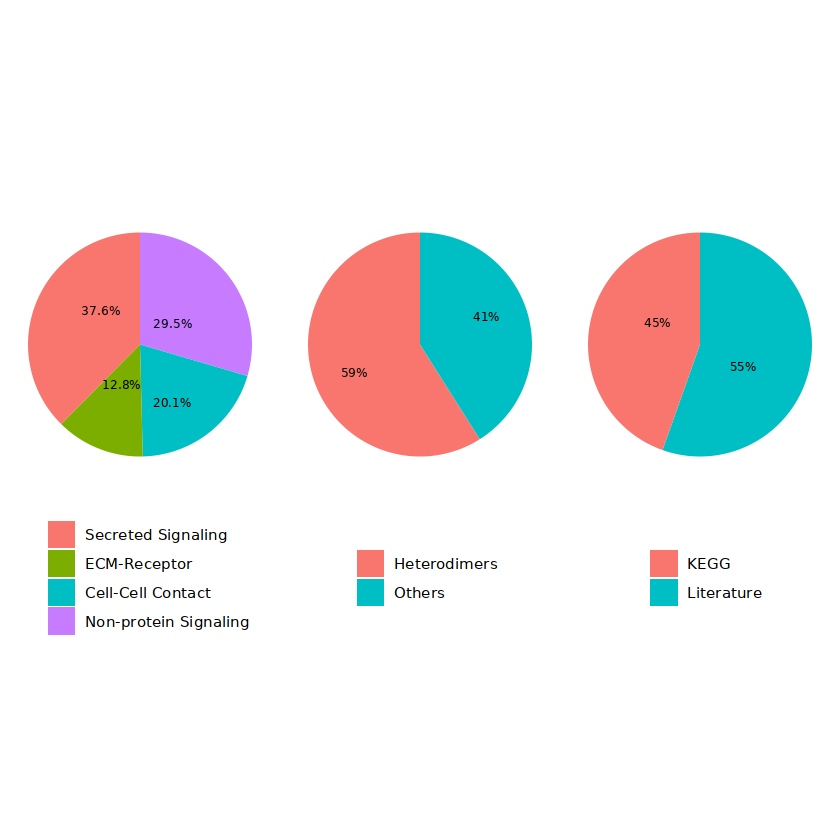

In [ ]:
#设置配受体数据库(CellChatDB):
CellChatDB <- CellChatDB.mouse #有人类(CellChatDB.human)和小鼠(CellChatDB.mouse)
showDatabaseCategory(CellChatDB) #查看描述该数据库组成的饼状图
dplyr::glimpse(CellChatDB$interaction) #查看数据库结构
#CellChatDB.use <- CellChatDB #直接使用CellChatDB全库进行细胞通讯分
CellChatDB.use <- subsetDB(CellChatDB, search = c("ECM-Receptor", 'Secreted Signaling', 'Cell-Cell Contact'))  #可选择Secreted Signaling、ECM-Receptor或Cell-Cell Contact
cellchat@DB <- CellChatDB.use

In [ ]:
# 数据预处理
cellchat <- subsetData(cellchat) #必选的step,取上一步CellChatDB.use中信号基因的表达矩阵子集,赋值到cellchat@data.Signaling
future::plan('multicore', workers = 32) # do parallel

cellchat <- identifyOverExpressedGenes(cellchat)
cellchat <- identifyOverExpressedInteractions(cellchat)

In [ ]:
# 计算结果赋值到cellchat@var.features：
# head(cellchat@var.features$features) #过表达信号基因名
# head(cellchat@var.features$features.info) #差异计算结果表
# cellchat <- projectData(cellchat, PPI.human) #将基因表达数据映射到PPI网络(可跳过);返回结果:cellchat@data.project


In [ ]:
#cellchat@data.signaling <- cellchat@data.signaling[rowSums(cellchat@data.signaling) > 0, , drop = FALSE]

In [ ]:
#########################——推断 cell-cell communication network——############################
# 计算细胞通讯概率
cellchat <- computeCommunProb(cellchat, raw.use = TRUE) #返回结果:cellchat@options$parameter;默认使用原始表达数据(cellchat@data.Signaling)，若想使用上一步PPI矫正数据,设置raw.use = TALSE
cellchat <- filterCommunication(cellchat, min.cells = 10) #细胞通讯过滤(设置每个亚群中进行细胞间通讯所需的最小细胞数)
cellchat <- computeCommunProbPathway(cellchat) #计算每个信号通路相关的所有配体-受体相互作用的通信结果
cellchat <- aggregateNet(cellchat) #计算细胞对间通讯的数量和概率强度
print("已计算computeCommunProb & computeCommunProbPathway")
saveRDS(cellchat,"Stereocell-Epi-SGN-cellchat.rds")
print("cellchat_plot.rds 已保存")

triMean is used for calculating the average gene expression per cell group. 
[1] ">>> Run CellChat on sc/snRNA-seq data <<< [2026-10-07 18:27:01]"
[1] ">>> CellChat inference is done. Parameter values are stored in `object@options$parameter` <<< [2026-10-07 18:36:46]"
[1] "已计算computeCommunProb & computeCommunProbPathway"
[1] "cellchat_plot.rds 已保存"


In [ ]:
cellchat <- readRDS('Stereocell-Epi-SGN-cellchat.rds')

In [ ]:
id <- 'Stereocell-SGN_Epi'

In [ ]:
groupSize <- as.numeric(table(cellchat@idents))

pdf(paste0(id, "-all-subcellttpe_netVisual_circle.pdf"))
#par(mfrow = c(1,2), xpd=TRUE)
p <- netVisual_circle(cellchat@net$count, vertex.weight = groupSize, weight.scale = T, label.edge= F, title.name = "Number of interactions")
print(p)
p <- netVisual_circle(cellchat@net$weight, vertex.weight = groupSize, weight.scale = T, label.edge= F, title.name = "Interaction weights/strength")
print(p)
dev.off()

png 
  2

In [ ]:
#逐个展示细胞亚群的互作信号强度——网图：
mat <- cellchat@net$weight
pdf(paste0(id, "-every-subcellttpe_netVisual_circle.pdf"))
lapply(1:nrow(mat), function(i) {
  mat2 <- matrix(0, nrow = nrow(mat), ncol = ncol(mat), dimnames = dimnames(mat))
  mat2[i, ] <- mat[i, ]
  p <- netVisual_circle(mat2, vertex.weight = groupSize, weight.scale = T, edge.weight.max = max(mat), title.name = rownames(mat)[i], edge.label.cex = 0.4, vertex.label.cex = 0.5)
  return(p)
})
dev.off()

[[1]]

[[2]]

[[3]]

[[4]]

[[5]]

[[6]]

[[7]]


png 
  2

In [ ]:
#逐个展示细胞亚群的互作信号强度——柱状图：
pdf(paste0(id, "-every-subcelltype_barplot.pdf"))
lapply(1:nrow(mat), function(i) {
  # 创建数据框
  df <- data.frame(cell_type = colnames(mat), weight = as.numeric(mat[i, ]))
  # 使用ggplot2创建柱状图
  p <- ggplot(df, aes(x = cell_type, y = weight, fill = cell_type)) +
    geom_bar(stat = "identity",fill = "steelblue", width=0.3) +
    labs(title = rownames(mat)[i], x = "celltype", y = "Signal Strength") +
    theme_classic() +
    theme(axis.text.x = element_text(angle = 45, hjust = 1), axis.text = element_text(size = 8)) 
  return(p)
})
dev.off()

[[1]]

[[2]]

[[3]]

[[4]]

[[5]]

[[6]]

[[7]]


png 
  2

In [ ]:
# 逐个信号通路展示：细胞亚群的互作
path <- unique(cellchat@netP$pathways)

lapply(path,function(pathways.show){
  try({
    pdf(
      paste0("Epi_pathway-",pathways.show,".pdf"),
      width=10,
      height=10,
      onefile=TRUE
    )

    # 1. Circle
    netVisual_aggregate(
      cellchat,
      signaling=pathways.show,
      layout="circle"
    )

    # 2. Heatmap
    grid::grid.newpage()
    p1 <- netVisual_heatmap(
      cellchat,
      signaling=pathways.show,
      color.heatmap="Reds"
    )
    print(p1)

    # 3. L-R contribution
    grid::grid.newpage()
    p2 <- netAnalysis_contribution(
      cellchat,
      signaling=pathways.show
    )
    print(p2)

    # 4. Signaling role
    grid::grid.newpage()

    extractEnrichedLR(
      cellchat,
      signaling=pathways.show,
      geneLR.return=FALSE
    )

    cellchat <- netAnalysis_computeCentrality(
      cellchat,
      slot.name="netP"
    )

    netAnalysis_signalingRole_network(
      cellchat,
      signaling=pathways.show,
      width=15,
      height=2.5,
      font.size=10
    )

    dev.off()

  },silent=FALSE)
})

Do heatmap based on a single object 


Do heatmap based on a single object 


Do heatmap based on a single object 


Do heatmap based on a single object 


Do heatmap based on a single object 


Do heatmap based on a single object 


Do heatmap based on a single object 


Do heatmap based on a single object 


Do heatmap based on a single object 


Do heatmap based on a single object 


Do heatmap based on a single object 


Do heatmap based on a single object 


Do heatmap based on a single object 


Do heatmap based on a single object 


Do heatmap based on a single object 


Do heatmap based on a single object 


Do heatmap based on a single object 


Do heatmap based on a single object 


Do heatmap based on a single object 


Do heatmap based on a single object 


Do heatmap based on a single object 


Do heatmap based on a single object 


Do heatmap based on a single object 


Do heatmap based on a single object 


Do heatmap based on a single object 


Do heatmap based on a sin

[[1]]
png 
  2 

[[2]]
png 
  2 

[[3]]
png 
  2 

[[4]]
png 
  2 

[[5]]
png 
  2 

[[6]]
png 
  2 

[[7]]
png 
  2 

[[8]]
png 
  2 

[[9]]
png 
  2 

[[10]]
png 
  2 

[[11]]
png 
  2 

[[12]]
png 
  2 

[[13]]
png 
  2 

[[14]]
png 
  2 

[[15]]
png 
  2 

[[16]]
png 
  2 

[[17]]
png 
  2 

[[18]]
png 
  2 

[[19]]
png 
  2 

[[20]]
png 
  2 

[[21]]
png 
  2 

[[22]]
png 
  2 

[[23]]
png 
  2 

[[24]]
png 
  2 

[[25]]
png 
  2 

[[26]]
png 
  2 

[[27]]
png 
  2 

[[28]]
png 
  2 

[[29]]
png 
  2 

[[30]]
png 
  2 

[[31]]
png 
  2 

[[32]]
png 
  2 

[[33]]
png 
  2 

[[34]]
png 
  2 

[[35]]
png 
  2 

[[36]]
png 
  2 

[[37]]
png 
  2 

[[38]]
png 
  2 

[[39]]
png 
  2 

[[40]]
png 
  2 

[[41]]
png 
  2 

[[42]]
png 
  2 

[[43]]
png 
  2 

[[44]]
png 
  2 

[[45]]
png 
  2 

[[46]]
png 
  2 

[[47]]
png 
  2 

[[48]]
png 
  2 

[[49]]
png 
  2

In [ ]:
sgn.use <- c(
  "SGN-Ic","SGN-Ib",
  "SGN-Ia","SGN-II"
)

glia.use <- c(
  "Hair Cells","ISC_OSC",
  "IPhC_IBC"
)

stopifnot(
  all(c(sgn.use,glia.use) %in% levels(cellchat@idents))
)

# Glia → SGN
p1 <- netVisual_bubble(
  cellchat,
  sources.use=glia.use,
  targets.use=sgn.use,
  remove.isolate=TRUE,
  angle.x=45
)

ggsave(
  "CellChat_Epi_to_SGN_bubble.pdf",
  p1,width=12,height=20
)

# SGN → Glia
p2 <- netVisual_bubble(
  cellchat,
  sources.use=sgn.use,
  targets.use=glia.use,
  remove.isolate=TRUE,
  angle.x=45
)

ggsave(
  "CellChat_SGN_to_Epi_bubble.pdf",
  p2,width=12,height=20
)

Comparing communications on a single object 


Comparing communications on a single object 




In [ ]:
# 所有显著配体–受体通讯
lr <- subsetCommunication(cellchat)

# 只保留 SGN 与 Glia 之间的两个方向
lr.cross <- lr[
  (lr$source %in% sgn.use & lr$target %in% glia.use) |
  (lr$source %in% glia.use & lr$target %in% sgn.use),
]

write.csv(
  lr.cross,
  "SGN_Epi_bidirectional_LR.csv",
  row.names = FALSE
)

# 导出强度矩阵，用于核实图中的强弱
write.csv(
  cellchat@net$weight,
  "SGN_Epi_CellChat_interaction_weights.csv"
)

In [ ]:
library(ggplot2)
library(dplyr)

input_file <- "SGN_Epi_bidirectional_LR.csv"

output_dir <- "CellChat_SGN_Epi_pathway_bubbles"
dir.create(output_dir, recursive=TRUE, showWarnings=FALSE)

lr <- read.csv(
  input_file,
  stringsAsFactors=FALSE,
  check.names=FALSE
)

required_cols <- c(
  "source","target","prob","pval",
  "interaction_name","interaction_name_2","pathway_name"
)

stopifnot(all(required_cols %in% colnames(lr)))

pathways <- c(
  "NCAM","FGF","LAMININ","NRXN","NRG","CADM","EPHA","CDH","PTPRM",
  "BMP","CNTN","NGL","SEMA3","NEGR","SEMA6","PTN","COLLAGEN","MPZ",
  "EPHB","TENASCIN","FN1","TGFb","SEMA5","JAM","GAS","IGF","SEMA7",
  "EGF","NOTCH","CLDN","PDGF","HSPG","CD46","AGRN","ncWNT","HGF",
  "RELN","L1CAM","OCLN"
)

sgn <- c(
  "SGN-Ic",
  "SGN-Ib",
  "SGN-Ia",
  "SGN-II"
)

epi <- c(
  "Hair Cells",
  "ISC_OSC",
  "IPhC_IBC"
)

# 只保留 SGN 与 Epi 之间、p < 0.05 且 prob > 0 的记录
lr <- lr %>%
  filter(
    pathway_name %in% pathways,
    is.finite(prob),
    is.finite(pval),
    prob > 0,
    pval < 0.05,
    (source %in% epi & target %in% sgn) |
      (source %in% sgn & target %in% epi)
  )

if(nrow(lr)==0){
  stop("没有符合条件的通讯记录，请检查细胞标签和通路名称。")
}

# 检查重复记录
if(anyDuplicated(
  lr[,c("source","target","interaction_name")]
)>0){
  stop("发现重复的 source-target-interaction_name，请先检查数据。")
}

# 所有图统一颜色范围
prob_max <- max(lr$prob)

make_bubble <- function(pathway,sources,targets,direction){

  df <- lr %>%
    filter(
      pathway_name==pathway,
      source %in% sources,
      target %in% targets
    )

  # 没有结果时保留一页提示
  if(nrow(df)==0){
    return(
      ggplot() +
        annotate(
          "text",
          x=0,
          y=0,
          label="No retained interactions (p < 0.05)"
        ) +
        labs(
          title=paste(pathway,direction,sep=" | ")
        ) +
        theme_void()
    )
  }

  # X轴：所有指定细胞组合
  x_levels <- unlist(
    lapply(
      sources,
      function(s) paste(s,targets,sep=" -> ")
    ),
    use.names=FALSE
  )

  # Y轴：该方向实际检出的LR对
  pair_table <- df %>%
    distinct(interaction_name,interaction_name_2) %>%
    arrange(interaction_name_2)

  pair_labels <- setNames(
    pair_table$interaction_name_2,
    pair_table$interaction_name
  )

  df <- df %>%
    mutate(
      cell_pair=factor(
        paste(source,target,sep=" -> "),
        levels=x_levels
      ),

      interaction_id=factor(
        interaction_name,
        levels=rev(pair_table$interaction_name)
      ),

      p_group=factor(
        ifelse(
          pval<0.01,
          "p < 0.01",
          "0.01 <= p < 0.05"
        ),
        levels=c(
          "p < 0.01",
          "0.01 <= p < 0.05"
        )
      )
    )

  ggplot(
    df,
    aes(
      x=cell_pair,
      y=interaction_id
    )
  ) +
    geom_point(
      aes(
        color=prob,
        size=p_group
      ),
      alpha=0.95
    ) +
    scale_color_gradientn(
      colours=c(
        "#29409E",
        "#1A99B8",
        "#8FCCA3",
        "#FCD462",
        "#C71A29"
      ),
      limits=c(0,prob_max),
      name="Raw prob"
    ) +
    scale_size_manual(
      values=c(
        "p < 0.01"=3.2,
        "0.01 <= p < 0.05"=1.9
      ),
      drop=FALSE,
      name="p-value"
    ) +
    scale_x_discrete(drop=FALSE) +
    scale_y_discrete(labels=pair_labels) +
    labs(
      title=paste(pathway,direction,sep=" | "),
      subtitle=paste0(
        nrow(pair_table),
        " ligand-receptor pairs; ",
        nrow(df),
        " communications"
      ),
      x=NULL,
      y=NULL,
      caption=paste(
        "All detected pairs in this direction; p < 0.05.",
        "Colors use a common raw-probability scale."
      )
    ) +
    theme_bw(base_size=10) +
    theme(
      axis.text.x=element_text(
        angle=55,
        hjust=1,
        vjust=1,
        size=8
      ),
      axis.text.y=element_text(size=9),
      panel.grid.minor=element_blank(),
      panel.grid.major=element_line(
        colour="#E1E6EC",
        linewidth=0.3
      ),
      plot.title=element_text(face="bold"),
      plot.caption=element_text(
        hjust=0,
        size=8
      ),
      plot.margin=margin(
        12,15,12,12
      )
    )
}

plots <- list()

for(pw in pathways){

  plots[[paste0(pw,"_Epi_to_SGN")]] <- make_bubble(
    pathway=pw,
    sources=epi,
    targets=sgn,
    direction="Epi -> SGN"
  )

  plots[[paste0(pw,"_SGN_to_Epi")]] <- make_bubble(
    pathway=pw,
    sources=sgn,
    targets=epi,
    direction="SGN -> Epi"
  )
}

# ============================================================
# 5. PDF保存函数
# ============================================================

save_pdf <- function(plot_list,filename,width,height){

  grDevices::pdf(
    file=filename,
    width=width,
    height=height,
    onefile=TRUE,
    useDingbats=FALSE
  )

  on.exit(
    grDevices::dev.off(),
    add=TRUE
  )

  for(p in plot_list){
    print(p)
  }
}

for(pw in pathways){

  keys <- c(
    paste0(pw,"_Epi_to_SGN"),
    paste0(pw,"_SGN_to_Epi")
  )

  n_pairs <- vapply(
    plots[keys],
    function(p){

      if("interaction_id" %in% names(p$data)){
        nlevels(p$data$interaction_id)
      }else{
        0L
      }

    },
    integer(1)
  )

  plot_height <- max(
    6,
    3.5 + 0.22*max(n_pairs)
  )

  save_pdf(
    plot_list=plots[keys],
    filename=file.path(
      output_dir,
      paste0(
        pw,
        "_SGN_Epi_bidirectional_bubble.pdf"
      )
    ),
    width=14,
    height=plot_height
  )
}

# ============================================================
# 7. 保存全部39条通路合集
#    39 × 2 = 78页
# ============================================================

save_pdf(
  plot_list=plots,
  filename=file.path(
    output_dir,
    "All_39_pathways_SGN_Epi_bubbles.pdf"
  ),
  width=14,
  height=13
)

message(
  "绘图完成，文件保存在：",
  output_dir
)

绘图完成，文件保存在：CellChat_SGN_Epi_pathway_bubbles



In [ ]:
main_pair_key <- function(x) {
  for (ch in c('\u2212', '\u2013', '\u2014')) x <- gsub(ch, '-', x, fixed=TRUE)
  x <- gsub('\uff0b', '+', x, fixed=TRUE)
  toupper(gsub('[[:space:]()\uff08\uff09]', '', x, perl=TRUE))
}

main_pair_spec <- function() {
x <- read.table(text='direction|family|ligand|receptor
SGN -> Epi|NCAM|Ncam1|Fgfr1
SGN -> Epi|FGF|Fgf10|Fgfr1
SGN -> Epi|FGF|Fgf10|Fgfr2
SGN -> Epi|NRG|Nrg1|Erbb4
SGN -> Epi|NRG|Nrg2|Erbb4
SGN -> Epi|NRG|Nrg3|Erbb4
SGN -> Epi|CADM|Cadm1|Nectin3
SGN -> Epi|CNTN|Cntn1|Nrcam
SGN -> Epi|PTPR|Lrfn5|Ptprd
SGN -> Epi|PTPR|Lrfn5|Ptprf
SGN -> Epi|NGL|Lrrc4c|Ntng1
Epi -> SGN|LAMININ|Lama2|Sv2b
Epi -> SGN|LAMININ|Lama2|Sv2c
Epi -> SGN|NRXN|Nrxn1|Clstn2
Epi -> SGN|NRXN|Nrxn1|Lrrtm3
Epi -> SGN|NRXN|Nrxn3|Nlgn1
Epi -> SGN|NRXN|Nrxn3|Lrrtm3
Epi -> SGN|CADM|Cadm1|Cadm1
Epi -> SGN|EPHA|Efna5|Epha4
Epi -> SGN|BMP|Bmp6|(Bmpr1a+Acvr2a)
Epi -> SGN|BMP|Bmp6|(Bmpr1a+Bmpr2)
Epi -> SGN|NGL|Lrrc4c|Ntng1
Epi -> SGN|SLIT|Slit2|Robo1
Epi -> SGN|SLIT|Slit2|Robo2', header=TRUE, sep='|',
    quote='', stringsAsFactors=FALSE, strip.white=TRUE)
  x$pair <- paste(x$ligand, x$receptor, sep=' - ')
  x$key <- main_pair_key(x$pair)
  x[!duplicated(x[c('direction','key')]),,drop=FALSE]
}

main_cell_label <- function(x) sub('^[0-9]+[.]', '', as.character(x))

# input: previous cfg, a CSV filename, or a CellChat result data.frame.
# Raw tables need source, target, prob, pval, interaction_name_2.
# With previous cfg, preserve its group names and probability color limit.
prepare_main_cfg <- function(input, sgn=NULL, epi=NULL, prob_max=NULL) {
  for (pkg in c('ggplot2','patchwork'))
    if (!requireNamespace(pkg, quietly=TRUE)) stop('Install package: ', pkg)
  old <- is.list(input) && !is.data.frame(input) && !is.null(input$sig)
  if (old) {
    x <- input$sig
    warning("Using input$sig only. Previously excluded pairs cannot be recovered; use the original CSV for this new selection.")
    if (is.null(sgn)) sgn <- input$sgn
    if (is.null(epi)) epi <- input$epi
    if (is.null(prob_max)) prob_max <- input$prob_max
  } else if (is.character(input) && length(input)==1L) {
    x <- read.csv(input, stringsAsFactors=FALSE, check.names=FALSE)
  } else x <- input
  if (!is.data.frame(x)) stop('input must be cfg, a CSV filename or a data.frame.')
  need <- c('source','target','prob','pval')
  if (!all(need %in% names(x))) stop('Missing columns: ',paste(setdiff(need,names(x)),collapse=', '))
  if (!is.numeric(x$prob) || !is.numeric(x$pval)) stop('prob and pval must be numeric.')
  x$source <- as.character(x$source); x$target <- as.character(x$target)
  if ('interaction_name_2' %in% names(x)) x$key <- main_pair_key(x$interaction_name_2)
  else if ('key' %in% names(x)) x$key <- main_pair_key(x$key)
  else stop('Need interaction_name_2 (or the previous cfg key column).')
  available <- unique(c(x$source,x$target))
  infer <- function(wanted) {
    vapply(wanted,function(z) {
      hit <- available[main_cell_label(available)==z]
      if (length(hit)!=1L) stop('Cannot identify group ',z,'. Supply exact sgn/epi names explicitly.')
      hit
    },character(1),USE.NAMES=FALSE)
  }
  if (is.null(sgn)) sgn <- infer(c('SGN-Ic','SGN-Ib','SGN-Ia','SGN-II'))
  if (is.null(epi)) epi <- infer(c('Hair Cells','IPhC_IBC','ISC_OSC'))
  if (anyDuplicated(c(sgn,epi))) stop('sgn and epi must be disjoint, unique group names.')
  x$direction <- ifelse(x$source %in% epi & x$target %in% sgn,'Epi -> SGN',
    ifelse(x$source %in% sgn & x$target %in% epi,'SGN -> Epi',NA_character_))
  spec <- main_pair_spec()
  ix <- match(paste(x$direction,x$key),paste(spec$direction,spec$key))
  matched <- x[!is.na(ix),,drop=FALSE]
  if ('pathway_name' %in% names(matched)) {
    expected <- spec$family[match(paste(matched$direction,matched$key),paste(spec$direction,spec$key))]
    mismatch <- !is.na(matched$pathway_name) & matched$pathway_name != expected
    if (any(mismatch)) stop('Pathway label differs from input CSV; inspect matched pathway_name.')
  }
  sig <- matched[is.finite(matched$prob) & matched$prob>0 &
    is.finite(matched$pval) & matched$pval<.05,,drop=FALSE]
  if (anyDuplicated(sig[c('direction','source','target','key')]))
    stop('Duplicate cell-pair / ligand-receptor records. Check input before plotting.')
  if (!nrow(sig)) stop('No selected significant records; check group and pair names.')
  spec$n_matched <- vapply(seq_len(nrow(spec)),function(i)
    sum(matched$direction==spec$direction[i] & matched$key==spec$key[i]),integer(1))
  spec$n_retained <- vapply(seq_len(nrow(spec)),function(i)
    sum(sig$direction==spec$direction[i] & sig$key==spec$key[i]),integer(1))
  if (any(spec$n_retained==0)) warning('Pairs with no retained records remain blank; inspect cfg_main$spec.')
  if (is.null(prob_max)) prob_max <- max(sig$prob)
  if (length(prob_max)!=1 || !is.finite(prob_max) || prob_max<max(sig$prob))
    stop('prob_max must cover all selected scores; scores must not be clipped.')
  list(spec=spec,sig=sig,sgn=sgn,epi=epi,prob_max=prob_max)
}

main_prob_scale <- function(cfg, fill=FALSE) {
  args <- list(colours=c('#29409E','#1A99B8','#8FCCA3','#FCD462','#C71A29'),
    limits=c(0,cfg$prob_max),name='Raw probability',na.value='#E8E8E8')
  do.call(if(fill) ggplot2::scale_fill_gradientn else ggplot2::scale_color_gradientn,args)
}

main_theme <- function() {
  ggplot2::theme_bw(base_size=11) + ggplot2::theme(
    plot.title=ggplot2::element_text(face='bold'),
    panel.grid.minor=ggplot2::element_blank(),
    panel.grid.major.x=ggplot2::element_blank(),
    strip.background=ggplot2::element_rect(fill='#EDF2F6',colour=NA),
    strip.text=ggplot2::element_text(face='bold'),
    plot.caption=ggplot2::element_text(size=8,hjust=0))
}

main_bubble <- function(cfg,direction,letter) {
  sp <- cfg$spec[cfg$spec$direction==direction,,drop=FALSE]
  d <- cfg$sig[cfg$sig$direction==direction & cfg$sig$key %in% sp$key,,drop=FALSE]
  send <- if(direction=='Epi -> SGN') cfg$epi else cfg$sgn
  receive <- if(direction=='Epi -> SGN') cfg$sgn else cfg$epi
  labels <- paste(sp$family,sp$pair,sep=' | ')
  # Complete grid preserves all groups and all empty combinations.
  grid <- expand.grid(source=send,target=receive,key=sp$key,stringsAsFactors=FALSE)
  d <- merge(grid,d[c('source','target','key','prob','pval')],
    by=c('source','target','key'),all.x=TRUE,sort=FALSE)
  d$source <- factor(d$source,levels=send)
  d$target <- factor(d$target,levels=receive)
  d$pair <- factor(labels[match(d$key,sp$key)],levels=rev(labels))
  d$p_group <- factor(ifelse(is.na(d$pval),NA,
    ifelse(d$pval<.01,'p < 0.01','0.01 <= p < 0.05')),
    levels=c('p < 0.01','0.01 <= p < 0.05'))
  short <- function(z) {
    z <- main_cell_label(z)
    z <- sub('^SGN-','',z)
    z
  }
  ggplot2::ggplot(d,ggplot2::aes(target,pair)) +
    ggplot2::geom_point(ggplot2::aes(colour=prob,size=p_group),na.rm=TRUE) +
    ggplot2::facet_grid(cols=ggplot2::vars(source),drop=FALSE,
      labeller=ggplot2::labeller(source=short)) + main_prob_scale(cfg) +
    ggplot2::scale_size_manual(values=c('p < 0.01'=3.5,'0.01 <= p < 0.05'=2),
      drop=FALSE,na.translate=FALSE,name='p-value') +
    ggplot2::scale_x_discrete(drop=FALSE,labels=short) +
    ggplot2::scale_y_discrete(drop=FALSE) +
    ggplot2::labs(title=paste(letter,direction,sep=' | '),x='Receiver (facet = sender)',y=NULL,
      caption='Blank = no retained record; shared raw-probability scale for A-C.') +
    main_theme() + ggplot2::theme(axis.text.x=ggplot2::element_text(size=8,angle=40,hjust=1))
}

plot_main_A <- function(cfg) main_bubble(cfg,'Epi -> SGN','A')
plot_main_B <- function(cfg) main_bubble(cfg,'SGN -> Epi','B')

In [ ]:
cfg_main <- prepare_main_cfg("SGN_Epi_bidirectional_LR.csv")

In [ ]:
plot_main_A <- function(cfg) {
  p <- main_bubble(cfg, "Epi -> SGN", "A")

  cell_pairs <- unlist(lapply(cfg$epi, function(s) {
    paste(main_cell_label(s), main_cell_label(cfg$sgn), sep = " -> ")
  }))

  p$data$cell_pair <- factor(
    paste(main_cell_label(p$data$source),
          main_cell_label(p$data$target), sep = " -> "),
    levels = cell_pairs
  )

  p +
    ggplot2::facet_null() +
    ggplot2::aes(x = cell_pair) +
    ggplot2::scale_x_discrete(drop = FALSE) +
    ggplot2::labs(x = NULL, y = NULL) +
    ggplot2::theme(
      axis.text.x = ggplot2::element_text(angle = 55, hjust = 1, size = 9),
      axis.text.y = ggplot2::element_text(size = 10),
      panel.grid.major.x = ggplot2::element_line(
        colour = "#E8E8E8", linewidth = 0.3
      )
    )
}

pA <- plot_main_A(cfg_main)

ggplot2::ggsave(
  "A_Epi_to_SGN_large_bubble.pdf",
  plot = pA,
  width = 7,
  height = 4
)

In [ ]:
plot_main_B <- function(cfg) {
  p <- main_bubble(cfg, "SGN -> Epi", "B")

  cell_pairs <- unlist(lapply(cfg$sgn, function(s) {
    paste(main_cell_label(s), main_cell_label(cfg$epi), sep = " -> ")
  }))

  p$data$cell_pair <- factor(
    paste(main_cell_label(p$data$source),
          main_cell_label(p$data$target), sep = " -> "),
    levels = cell_pairs
  )

  p +
    ggplot2::facet_null() +
    ggplot2::aes(x = cell_pair) +
    ggplot2::scale_x_discrete(drop = FALSE) +
    ggplot2::labs(x = NULL, y = NULL) +
    ggplot2::theme(
      axis.text.x = ggplot2::element_text(angle = 55, hjust = 1, size = 9),
      axis.text.y = ggplot2::element_text(size = 10),
      panel.grid.major.x = ggplot2::element_line(
        colour = "#E8E8E8", linewidth = 0.3
      )
    )
}

pB <- plot_main_B(cfg_main)

ggplot2::ggsave(
  "B_SGN_to_Epi_large_bubble.pdf",
  plot = pB,
  width = 6,
  height = 4
)

In [ ]:
cellchat <- readRDS('/data/work/Stereocell/Epi-SGN/Epi和SGN的cellchat/Stereocell-Epi-SGN-cellchat.rds')

In [ ]:
net_weight <- cellchat@net$weight
net_count  <- cellchat@net$count

keep_fraction <- 0.5

positive_weights <- net_weight[
  is.finite(net_weight) & net_weight > 0
]

if (!length(positive_weights)) stop("没有可绘制的互作。")

cutoff <- unname(
  quantile(positive_weights, probs = 1 - keep_fraction)
)

# 数量图、强度图使用同一套连线
keep <- is.finite(net_weight) &
        net_weight > 0 &
        net_weight >= cutoff

net_weight[!keep] <- 0
net_count[!keep]  <- 0

# 节点大小表示各群细胞数
group_size <- as.numeric(
  table(cellchat@idents)[rownames(net_weight)]
)

plot_circle <- function(net, title) {
  CellChat::netVisual_circle(
    net,
    vertex.weight = group_size,
    vertex.size.max = 20,
    vertex.label.cex = 0.9,
    weight.scale = TRUE,
    edge.width.max = 8,
    edge.curved = 0.2,
    arrow.size = 0.3,
    label.edge = FALSE,
    remove.isolate = FALSE,
    title.name = title
  )
}

In [ ]:
library(igraph)

save_count_circle <- function(
    filename = "SGN_Epi_all_pathways_filtered_count.pdf") {

  mat <- as.matrix(net_count)
  mat[!is.finite(mat)] <- 0

  g <- graph_from_adjacency_matrix(
    mat, mode = "directed", weighted = TRUE, diag = TRUE
  )

  if (ecount(g) == 0) stop("没有可绘制的连线。")

  node_colors <- setNames(
    rep_len(
      c("#E41A1C", "#377EB8", "#4DAF4A",
        "#984EA3", "#F29403", "#F781BF", "#BC9DCC"),
      vcount(g)
    ),
    V(g)$name
  )

  n_cells <- as.numeric(
    table(cellchat@idents)[V(g)$name]
  )

  if (anyNA(n_cells) || max(n_cells) <= 0) {
    stop("细胞群名称与 cellchat@idents 不匹配。")
  }

  sender <- ends(g, E(g), names = TRUE)[, 1]

  # 圆形布局及朝外的自环方向
  coords <- layout_in_circle(g)
  loop_angle <- -atan2(coords[, 2], coords[, 1])
  edge_loop_angle <- loop_angle[match(sender, V(g)$name)]

  grDevices::pdf(
    filename,
    width = 8, height = 8,
    useDingbats = FALSE
  )
  on.exit(grDevices::dev.off(), add = TRUE)

  par(mfrow = c(1, 1), mar = c(1, 1, 3, 1))

  plot(
    g,
    layout = coords,
    vertex.color = unname(node_colors[V(g)$name]),
    vertex.frame.color = NA,
    vertex.size = 8 + 18 * n_cells / max(n_cells),
    vertex.label.color = "black",
    vertex.label.cex = 0.9,
    edge.color = adjustcolor(
      unname(node_colors[sender]), alpha.f = 0.65
    ),
    edge.width = 0.5 + 7.5 * E(g)$weight / max(E(g)$weight),
    edge.arrow.size = 0.3,
    edge.curved = 0.2,
    edge.loop.angle = edge_loop_angle,
    main = "Interaction count: stronger connections",
    margin = 0.3
  )

  invisible(filename)
}


# 强度图：自环朝节点外侧展开
save_weight_circle <- function(
    filename = "SGN_Epi_all_pathways_filtered_weight.pdf") {

  mat <- as.matrix(net_weight)
  mat[!is.finite(mat)] <- 0

  g <- graph_from_adjacency_matrix(
    mat, mode = "directed", weighted = TRUE, diag = TRUE
  )

  if (ecount(g) == 0) stop("没有可绘制的连线。")

  node_colors <- setNames(
    rep_len(
      c("#E41A1C", "#377EB8", "#4DAF4A",
        "#984EA3", "#F29403", "#F781BF", "#BC9DCC"),
      vcount(g)
    ),
    V(g)$name
  )

  n_cells <- as.numeric(
    table(cellchat@idents)[V(g)$name]
  )

  if (anyNA(n_cells) || max(n_cells) <= 0) {
    stop("细胞群名称与 cellchat@idents 不匹配。")
  }

  sender <- ends(g, E(g), names = TRUE)[, 1]

  # 圆形布局及朝外的自环方向
  coords <- layout_in_circle(g)
  loop_angle <- -atan2(coords[, 2], coords[, 1])
  edge_loop_angle <- loop_angle[match(sender, V(g)$name)]

  grDevices::pdf(
    filename,
    width = 8, height = 8,
    useDingbats = FALSE
  )
  on.exit(grDevices::dev.off(), add = TRUE)

  par(mfrow = c(1, 1), mar = c(1, 1, 3, 1))

  plot(
    g,
    layout = coords,
    vertex.color = unname(node_colors[V(g)$name]),
    vertex.frame.color = NA,
    vertex.size = 8 + 18 * n_cells / max(n_cells),
    vertex.label.color = "black",
    vertex.label.cex = 0.9,
    edge.color = adjustcolor(
      unname(node_colors[sender]), alpha.f = 0.65
    ),
    edge.width = 0.5 + 7.5 * E(g)$weight / max(E(g)$weight),
    edge.arrow.size = 0.3,
    edge.curved = 0.2,
    edge.loop.angle = edge_loop_angle,
    main = "Interaction strength: stronger connections",
    margin = 0.3
  )

  invisible(filename)
}


# 分别运行并保存
save_count_circle()
save_weight_circle()